<a href="https://colab.research.google.com/github/clive-strath/SemProject_MLEngine/blob/main/CoinSprout_Risk_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CoinSprout: Step 1, Risk Classifier

**Goal:** take a user's questionnaire answers and predict their risk category (Conservative, Moderate or Aggressive).

**What this notebook does**
1. Generates a synthetic dataset (we have no real users yet)
2. Trains three models: Logistic Regression, Random Forest and SVM
3. Compares them fairly, using the same data, the same metric and the same cross-validation
4. Shows *why* the models decide what they do (explainability)
5. Saves the best model, plus a JSON file you can use inside the Kotlin app

**Important:** the data is synthetic, so treat the results as a proof of concept. When you run your pilot questionnaire, replace Section 1 with your real data and re-run everything else unchanged.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score

SEED = 42
np.random.seed(SEED)

## 1. Create the dataset

Each row is one imaginary user who answered five questions (scale 1 to 5, except `goal_type`, which is 1 to 3).

The label comes from a weighted score **plus random noise**. The noise imitates real people, who answer inconsistently. Without it, any model would score about 100% by simply re-learning our formula, which proves nothing.

Note that `goal_type` is **not** used in the score. It is a decoy, so a good model should learn to ignore it. We will check that later.

> **When you have real pilot data:** load your CSV here instead, keeping the same column names and a `risk_category` column.

In [2]:
n = 1000
df = pd.DataFrame({
    "time_horizon":          np.random.randint(1, 6, n),
    "risk_tolerance":        np.random.randint(1, 6, n),
    "income_stability":      np.random.randint(1, 6, n),
    "investment_experience": np.random.randint(1, 6, n),
    "goal_type":             np.random.randint(1, 4, n),   # decoy feature
})

score = (0.25 * df.time_horizon
         + 0.35 * df.risk_tolerance
         + 0.20 * df.income_stability
         + 0.20 * df.investment_experience)

NOISE = 0.3          # try 0.5 for a harder, more realistic task
score_noisy = score + np.random.normal(0, NOISE, n)

df["risk_category"] = pd.cut(
    score_noisy,
    bins=[-np.inf, 2.2, 3.4, np.inf],
    labels=["Conservative", "Moderate", "Aggressive"],
)

df.head()

,time_horizon,risk_tolerance,income_stability,investment_experience,goal_type,risk_category
0,4,4,4,3,3,Aggressive
1,5,4,3,5,1,Aggressive
2,3,4,2,1,2,Moderate
3,5,4,1,5,1,Aggressive
4,5,5,5,2,2,Aggressive


### Check the class balance
If one category is tiny, models can look good while ignoring it. This is why we use *macro*-F1 later, which treats all three categories equally.

risk_category
Moderate        549
Aggressive      291
Conservative    160
Name: count, dtype: int64


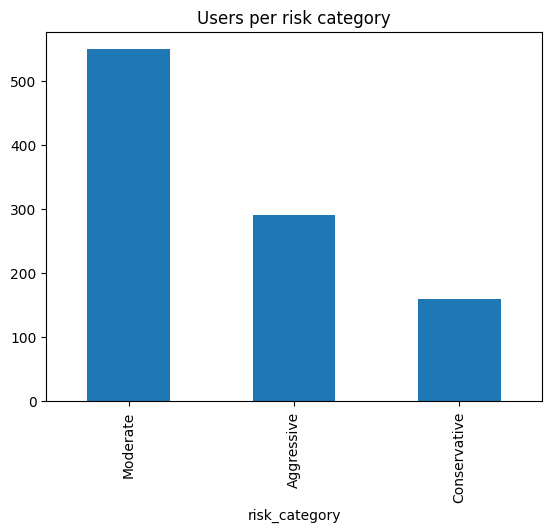

In [3]:
print(df["risk_category"].value_counts())
df["risk_category"].value_counts().plot(kind="bar", title="Users per risk category")
plt.show()

## 2. Train / test split

We hold back 20% of users that the models never see during training. `stratify=y` keeps the category proportions the same in both parts.

In [4]:
FEATURES = ["time_horizon", "risk_tolerance", "income_stability", "investment_experience", "goal_type"]
X = df[FEATURES]
y = df["risk_category"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 5)  Test: (200, 5)


## 3. Define the three models

Each model sits in a **Pipeline** with a scaler. This keeps scaling *inside* cross-validation, so information from the validation folds can't leak into training.

`GridSearchCV` tries each combination of settings (the "grid") and picks the best one using 5-fold cross-validation scored on macro-F1.

| Model | In one line |
|---|---|
| Logistic Regression | Weighs each answer and adds them up. Easy to explain. |
| Random Forest | Many decision trees voting together. |
| SVM | Finds the best boundary between categories. |

In [5]:
models = {
    "Logistic Regression": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100]},
    ),
    "Random Forest": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", RandomForestClassifier(random_state=SEED, class_weight="balanced"))]),
        {"clf__n_estimators": [100, 300],
         "clf__max_depth": [3, 5, 8, None],
         "clf__min_samples_leaf": [1, 5, 10]},
    ),
    "SVM": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", SVC(class_weight="balanced"))]),
        {"clf__C": [0.1, 1, 10, 100],
         "clf__gamma": ["scale", 0.01, 0.1, 1],
         "clf__kernel": ["rbf", "linear"]},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 4. Train and tune all three


In [6]:
fitted = {}
rows = []

for name, (pipe, grid) in models.items():
    search = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    pred = best.predict(X_test)

    fitted[name] = best
    rows.append({
        "Model": name,
        "CV macro-F1": round(search.best_score_, 3),
        "Test macro-F1": round(f1_score(y_test, pred, average="macro"), 3),
        "Test accuracy": round(accuracy_score(y_test, pred), 3),
        "Best settings": search.best_params_,
    })
    print(f"Done: {name}")

results = pd.DataFrame(rows).sort_values("Test macro-F1", ascending=False).reset_index(drop=True)
results

Done: Logistic Regression
Done: Random Forest
Done: SVM


,Model,CV macro-F1,Test macro-F1,Test accuracy,Best settings
0,Logistic Regression,0.789,0.790,0.795,{'clf__C': 10}
1,SVM,0.789,0.771,0.775,"{'clf__C': 10, 'clf__gamma': 0.1, 'clf__kernel..."
2,Random Forest,0.769,0.759,0.775,"{'clf__max_depth': 8, 'clf__min_samples_leaf':..."


## 5. Compare the results

**How to read the table**
- **CV macro-F1** is the average score across 5 training folds. It is the fairest number for choosing a model.
- **Test macro-F1** is the score on the 20% held back. It is your final, honest result.
- If the scores are within about 0.02 of each other, treat them as a **tie**. Then choose the simpler, more explainable model (usually Logistic Regression).

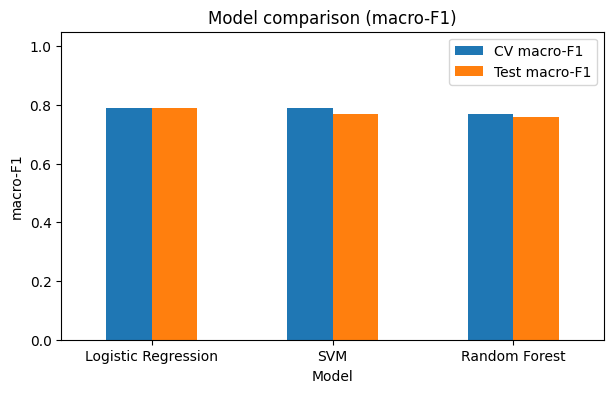

In [7]:
ax = results.set_index("Model")[["CV macro-F1", "Test macro-F1"]].plot(kind="bar", ylim=(0, 1.05), rot=0, figsize=(7, 4))
ax.set_title("Model comparison (macro-F1)")
ax.set_ylabel("macro-F1")
plt.show()

### Detailed report and confusion matrix for every model
The confusion matrix shows *which* categories get mixed up. Mistakes between neighbours (Moderate vs Aggressive) are expected. Conservative predicted as Aggressive would be a serious problem.

Logistic Regression
              precision    recall  f1-score   support

Conservative       0.66      0.91      0.76        32
    Moderate       0.86      0.75      0.80       110
  Aggressive       0.79      0.83      0.81        58

    accuracy                           0.80       200
   macro avg       0.77      0.83      0.79       200
weighted avg       0.81      0.80      0.80       200

Random Forest
              precision    recall  f1-score   support

Conservative       0.70      0.72      0.71        32
    Moderate       0.79      0.80      0.80       110
  Aggressive       0.79      0.76      0.77        58

    accuracy                           0.78       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.78      0.78      0.78       200

SVM
              precision    recall  f1-score   support

Conservative       0.63      0.91      0.74        32
    Moderate       0.85      0.72      0.78       110
  Aggressive       0.77      0.81    

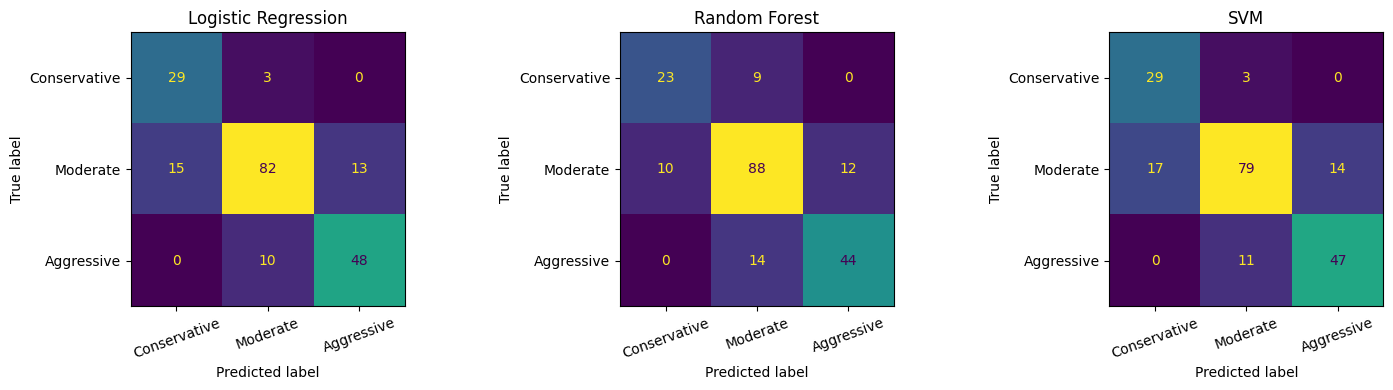

In [8]:
labels = ["Conservative", "Moderate", "Aggressive"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, fitted.items()):
    pred = model.predict(X_test)
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, labels=labels))
    cm = confusion_matrix(y_test, pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, xticks_rotation=20)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 6. Explainability: why does the model decide this?

This is the part that supports CoinSprout's promise: *"Because you're a Moderate Grower…"*

**Logistic Regression coefficients:** a positive number means a higher answer pushes the user *toward* that category. **Random Forest importances:** how much each question mattered overall.

Check that `goal_type` (the decoy) shows up as near zero. If it does, the models have learned the real pattern.

Logistic Regression coefficients (per category):


,time_horizon,risk_tolerance,income_stability,investment_experience,goal_type
Aggressive,2.25,3.27,1.81,1.60,0.05
Conservative,-2.33,-3.26,-1.71,-1.62,-0.04
Moderate,0.08,-0.00,-0.10,0.02,-0.01


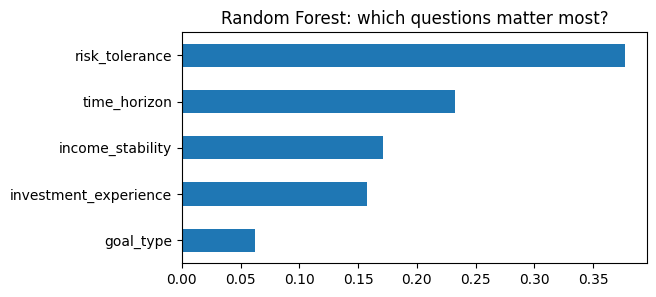

In [9]:
lr = fitted["Logistic Regression"].named_steps["clf"]
coef = pd.DataFrame(lr.coef_, index=lr.classes_, columns=FEATURES).round(2)
print("Logistic Regression coefficients (per category):")
display(coef)

rf = fitted["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", title="Random Forest: which questions matter most?", figsize=(6, 3))
plt.show()

## 7. Try it on one person

This is exactly what the app will do when a user finishes the questionnaire.

In [10]:
person = pd.DataFrame([{
    "time_horizon": 4,
    "risk_tolerance": 3,
    "income_stability": 2,
    "investment_experience": 1,
    "goal_type": 2,
}])

for name, model in fitted.items():
    proba = model.predict_proba(person)[0] if hasattr(model.named_steps["clf"], "predict_proba") else None
    label = model.predict(person)[0]
    print(f"{name:20s} -> {label}", "" if proba is None else dict(zip(model.classes_, proba.round(2))))

Logistic Regression  -> Moderate {'Aggressive': np.float64(0.01), 'Conservative': np.float64(0.12), 'Moderate': np.float64(0.87)}
Random Forest        -> Moderate {'Aggressive': np.float64(0.06), 'Conservative': np.float64(0.05), 'Moderate': np.float64(0.89)}
SVM                  -> Moderate 


## 8. Save the winner

The default below picks the model with the best test macro-F1. **Change `chosen` by hand** if you prefer another (for example Logistic Regression, if it is within 0.02 of the best). That is a legitimate and well-justified decision.

We save two things:
- `risk_model.joblib`: the full model, for a Python/FastAPI service
- `risk_lr_for_kotlin.json`: the Logistic Regression numbers, so the Android app can run the model on the phone with no server

In [11]:
chosen = results.loc[0, "Model"]     # or set manually, e.g. chosen = "Logistic Regression"
print("Saving:", chosen)
joblib.dump(fitted[chosen], "risk_model.joblib")

# Export Logistic Regression so Kotlin can compute it directly
pipe = fitted["Logistic Regression"]
scaler = pipe.named_steps["scale"]
lr = pipe.named_steps["clf"]
export = {
    "features": FEATURES,
    "classes": list(lr.classes_),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "coef": lr.coef_.tolist(),
    "intercept": lr.intercept_.tolist(),
}
with open("risk_lr_for_kotlin.json", "w") as f:
    json.dump(export, f, indent=2)

print("Saved risk_model.joblib and risk_lr_for_kotlin.json")

Saving: Logistic Regression
Saved risk_model.joblib and risk_lr_for_kotlin.json


## 9. Download the files

Run this cell to download both files to your computer (Colab only).

In [12]:
try:
    from google.colab import files
    files.download("risk_model.joblib")
    files.download("risk_lr_for_kotlin.json")
except ImportError:
    print("Not running in Colab. The files are saved in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>